# Week 7 final: 16-base-code multilabel ECG classification

**Scope.** This notebook consolidates the first Week 7 multilabel baseline and the subsequent imbalance and window experiments. It recomputes validation metrics and plots from saved predictions and histories. It does **not** retrain models, load waveforms, or read held-out test labels. The executed training workflows and checkpoints remain in the linked `experimental/` directories.

**Prediction target.** Each of 16 outputs represents presence of a selected base ICD-10 string in the deposited diagnosis annotations linked to an ECG record. The immutable source vocabulary is the 19 exact selected strings in `Data/DiseaseCode.csv`. An output zero means no matching selected annotation was deposited; it does **not** establish clinical absence. These are neither ECG diagnostic statements nor independently adjudicated ECG-time disease states.

**Evidence boundary.** All performance results below come from the established patient-level validation partition. The frozen test set is not evaluated. Figures are descriptive research aids, not clinical interpretations. Source notebooks: [baseline](experimental/multilabel_base16/Week7_Base16_Multilabel.ipynb), [imbalance strategies](experimental/imbalance_strategies/Week7_Imbalance_Strategies.ipynb), and [window strategies](experimental/window_augmentation/Week7_Window_Augmentation.ipynb).

In [1]:
from pathlib import Path
import sys, json, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve
from IPython.display import display

ROOT=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'Data/AttributesDictionary.csv').is_file())
W7=ROOT/'new work/Week7'
BASE=W7/'experimental/multilabel_base16'
IMB=W7/'experimental/imbalance_strategies'
WIN=W7/'experimental/window_augmentation'
for p in [BASE,IMB,WIN]: assert p.is_dir(),p
assert Path(sys.executable).resolve()==(ROOT/'venv/bin/python').resolve(), 'Select the existing project venv kernel.'
plt.rcParams.update({'figure.dpi':125,'axes.grid':True,'grid.alpha':.2,'axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_rows',40)
print('Project:',ROOT)
print('Kernel:',sys.executable,'| Python',platform.python_version(),'| PyTorch',torch.__version__)
print('CUDA available in this kernel:',torch.cuda.is_available())
if torch.cuda.is_available(): print('GPU:',torch.cuda.get_device_name(0))
print('Analysis uses saved train/validation artifacts only; no GPU, training, or waveform access required.')

Project: /home/souhit/Documents/Research/Pediatric_ECG
Kernel: /home/souhit/Documents/Research/Pediatric_ECG/venv/bin/python | Python 3.13.5 | PyTorch 2.6.0+cu124
CUDA available in this kernel: True
GPU: NVIDIA GeForce RTX 3060 Laptop GPU
Analysis uses saved train/validation artifacts only; no GPU, training, or waveform access required.


**Finding.** The notebook runs in the existing project virtual environment. CUDA status is reported from this kernel for provenance; the synthesis only reads saved artifacts and does not rely on GPU availability. The original training notebooks recorded CUDA execution on the RTX 3060 Laptop GPU.

In [2]:
mapping=json.loads((BASE/'target_mapping.json').read_text())
exact=mapping['exact_codes'];codes=mapping['base_codes_in_model_order'];base_of=mapping['exact_to_base']
assert len(exact)==19 and len(set(exact))==19 and len(codes)==16 and len(set(codes))==16
book=pd.read_csv(ROOT/'Data/DiseaseCode.csv',keep_default_na=False)
assert set(exact).issubset(set(book['ICD-10 Code']))
map_table=book[book['ICD-10 Code'].isin(exact)][['Disease Type','Disease Category','ICD-10 Code']].copy()
assert map_table['ICD-10 Code'].tolist()==exact
map_table['16-target base code']=map_table['ICD-10 Code'].map(base_of)
display(map_table.rename(columns={'ICD-10 Code':'19-string source code'}))
print('Targets in model order:',codes)

,Disease Type,Disease Category,19-string source code,16-target base code
0,Myocarditis,Fulminant myocarditis,(F) I40.0,I40.0
1,Myocarditis,Viral myocarditis,(V) I40.0,I40.0
2,Myocarditis,Acute myocarditis,I40.9,I40.9
3,Myocarditis,Myocarditis,I51.4,I51.4
4,Cardiomyopathy,Dilated cardiomyopathy,I42.0,I42.0
5,Cardiomyopathy,Hypertrophic cardiomyopathy,I42.2,I42.2
6,Cardiomyopathy,Cardiomyopathy,I42.9,I42.9
7,Cardiomyopathy,Noncompaction of the ventricular myocardium,Q24.8,Q24.8
8,Kawasaki disease,Kawasaki disease,M30.3,M30.3
9,Congenital \nheart disease,Ventricular septal defect,Q21.0,Q21.0


Targets in model order: ['I40.0', 'I40.9', 'I51.4', 'I42.0', 'I42.2', 'I42.9', 'Q24.8', 'M30.3', 'Q21.0', 'Q21.1', 'Q21.2', 'Q21.3', 'Q22.1', 'Q25.0', 'Q25.6', 'I37.0']


**Finding.** Only the locally qualified `I40.0` and `Q21.1` variants are consolidated: `(F) I40.0` and `(V) I40.0` map to `I40.0`; `Q21.1`, `(FO) Q21.1`, and `(OSD) Q21.1` map to `Q21.1`. Every other exact string maps to itself. The table preserves local categories alongside the original strings; it does not imply the qualifiers are standard ICD-10 subcodes. Multiple selected exact strings can activate multiple targets on one record. The source strings remain available in the mapping and checkpoints.

In [3]:
# Exact Week 7 ResNet-1D architecture, embedded here for inspection and inference.
# The original implementation remains in NoteBooks/Week5/models.py.
import torch.nn as nn
class ResidualBlock1D(nn.Module):
 def __init__(self,in_channels,out_channels,stride=1,downsample=None):
  super().__init__()
  self.conv1=nn.Conv1d(in_channels,out_channels,kernel_size=7,stride=stride,padding=3,bias=False)
  self.bn1=nn.BatchNorm1d(out_channels)
  self.relu=nn.ReLU(inplace=True)
  self.conv2=nn.Conv1d(out_channels,out_channels,kernel_size=7,stride=1,padding=3,bias=False)
  self.bn2=nn.BatchNorm1d(out_channels)
  self.downsample=downsample
 def forward(self,x):
  identity=x
  out=self.relu(self.bn1(self.conv1(x)))
  out=self.bn2(self.conv2(out))
  if self.downsample is not None:identity=self.downsample(x)
  return self.relu(out+identity)

class ResNet1D(nn.Module):
 def __init__(self,num_classes=16):
  super().__init__()
  self.in_channels=32
  self.conv1=nn.Conv1d(12,32,kernel_size=15,stride=2,padding=7,bias=False)
  self.bn1=nn.BatchNorm1d(32)
  self.relu=nn.ReLU(inplace=True)
  self.maxpool=nn.MaxPool1d(kernel_size=3,stride=2,padding=1)
  self.layer1=self._make_layer(32,blocks=2,stride=1)
  self.layer2=self._make_layer(64,blocks=2,stride=2)
  self.layer3=self._make_layer(128,blocks=2,stride=2)
  self.avgpool=nn.AdaptiveAvgPool1d(1)
  self.fc=nn.Linear(128,num_classes)
 def _make_layer(self,out_channels,blocks,stride):
  downsample=None
  if stride!=1 or self.in_channels!=out_channels:
   downsample=nn.Sequential(nn.Conv1d(self.in_channels,out_channels,kernel_size=1,stride=stride,bias=False),
                            nn.BatchNorm1d(out_channels))
  layers=[ResidualBlock1D(self.in_channels,out_channels,stride,downsample)]
  self.in_channels=out_channels
  layers += [ResidualBlock1D(self.in_channels,out_channels) for _ in range(1,blocks)]
  return nn.Sequential(*layers)
 def forward(self,x):
  x=self.maxpool(self.relu(self.bn1(self.conv1(x))))
  x=self.layer3(self.layer2(self.layer1(x)))
  return self.fc(torch.flatten(self.avgpool(x),1))

checkpoint_path=BASE/'resnet1d_base16_best.pth'
checkpoint=torch.load(checkpoint_path,map_location='cpu',weights_only=True)
assert checkpoint['base_codes_in_model_order']==codes
assert checkpoint['original_exact_codes']==exact
assert checkpoint['exact_to_base']==base_of
assert checkpoint['num_classes']==16 and checkpoint['input_samples']==5000
model=ResNet1D(num_classes=16).cpu()
model.load_state_dict(checkpoint['model_state_dict'],strict=True)
model.eval()
with torch.inference_mode():
 logits=model(torch.zeros(1,12,5000))
assert logits.shape==(1,16) and torch.isfinite(logits).all()
print('Loaded checkpoint:',checkpoint_path.name,'| epoch:',checkpoint['epoch'])
print('Parameters:',sum(p.numel() for p in model.parameters()),'| input:',(12,5000),'| outputs:',len(codes))
display(pd.DataFrame([{'stage':'Stem','output channels':32,'blocks':1},
 {'stage':'Residual layer 1','output channels':32,'blocks':2},
 {'stage':'Residual layer 2','output channels':64,'blocks':2},
 {'stage':'Residual layer 3','output channels':128,'blocks':2},
 {'stage':'Global average pool + linear','output channels':16,'blocks':1}]))

LEAD_INDEX={name.upper():i for i,name in enumerate(checkpoint['lead_order'])}
def preprocess_first_window(signal,signal_leads):
 """Convert a 500 Hz [samples, present_leads] NumPy signal to the Week 7 [1,12,5000] tensor."""
 signal=np.asarray(signal)
 assert signal.ndim==2 and signal.shape[1]==len(signal_leads) and len(signal)>0
 assert np.isfinite(signal).all()
 x=np.zeros((12,5000),dtype=np.float32)
 for j,lead in enumerate(signal_leads):
  k=LEAD_INDEX[lead.upper()]
  v=signal[:5000,j].astype(np.float32);sd=v.std()
  x[k,:len(v)]=(v-v.mean())/sd if sd>1e-8 else 0
 return torch.from_numpy(x).unsqueeze(0)
def predict_preprocessed(x,threshold=.5):
 """Return 16 code probabilities and fixed-threshold flags for a preprocessed [batch,12,5000] tensor."""
 assert isinstance(x,torch.Tensor) and x.ndim==3 and tuple(x.shape[1:])==(12,5000)
 with torch.inference_mode():p=torch.sigmoid(model(x.cpu())).numpy()
 return p,p>=threshold


Loaded checkpoint: resnet1d_base16_best.pth | epoch: 8
Parameters: 550736 | input: (12, 5000) | outputs: 16


,stage,output channels,blocks
0,Stem,32,1
1,Residual layer 1,32,2
2,Residual layer 2,64,2
3,Residual layer 3,128,2
4,Global average pool + linear,16,1


**Finding.** The selected **model architecture and checkpoint-loading code are now inside this notebook**. The original checkpoint weights remain in the separate preserved `.pth` file; running this cell loads them into the embedded `ResNet1D` class and checks its 16-output forward pass on a synthetic zero tensor. The model has no clinical meaning on that synthetic input, so no probabilities are interpreted. `preprocess_first_window` and `predict_preprocessed` make the saved model callable on appropriately sampled ECG arrays without changing any experiment artifact. The architecture is functionally identical to `NoteBooks/Week5/models.py`; the original training notebook contains the full training loop.

,item,value
0,patient split,"sorted IDs, random.Random(42), floor 70/15/15"
1,train records / patients,"9,943 / 8,150"
2,validation records / patients,"2,169 / 1,746"
3,waveform input,raw first 5000 samples at 500 Hz; anatomical 1...
4,architecture,NoteBooks/Week5/models.py:ResNet1D(num_classes...
5,optimization,"unweighted BCEWithLogitsLoss; Adam lr=0.0003, ..."
6,checkpoint selection,"minimum validation BCE, min delta 1e-5"


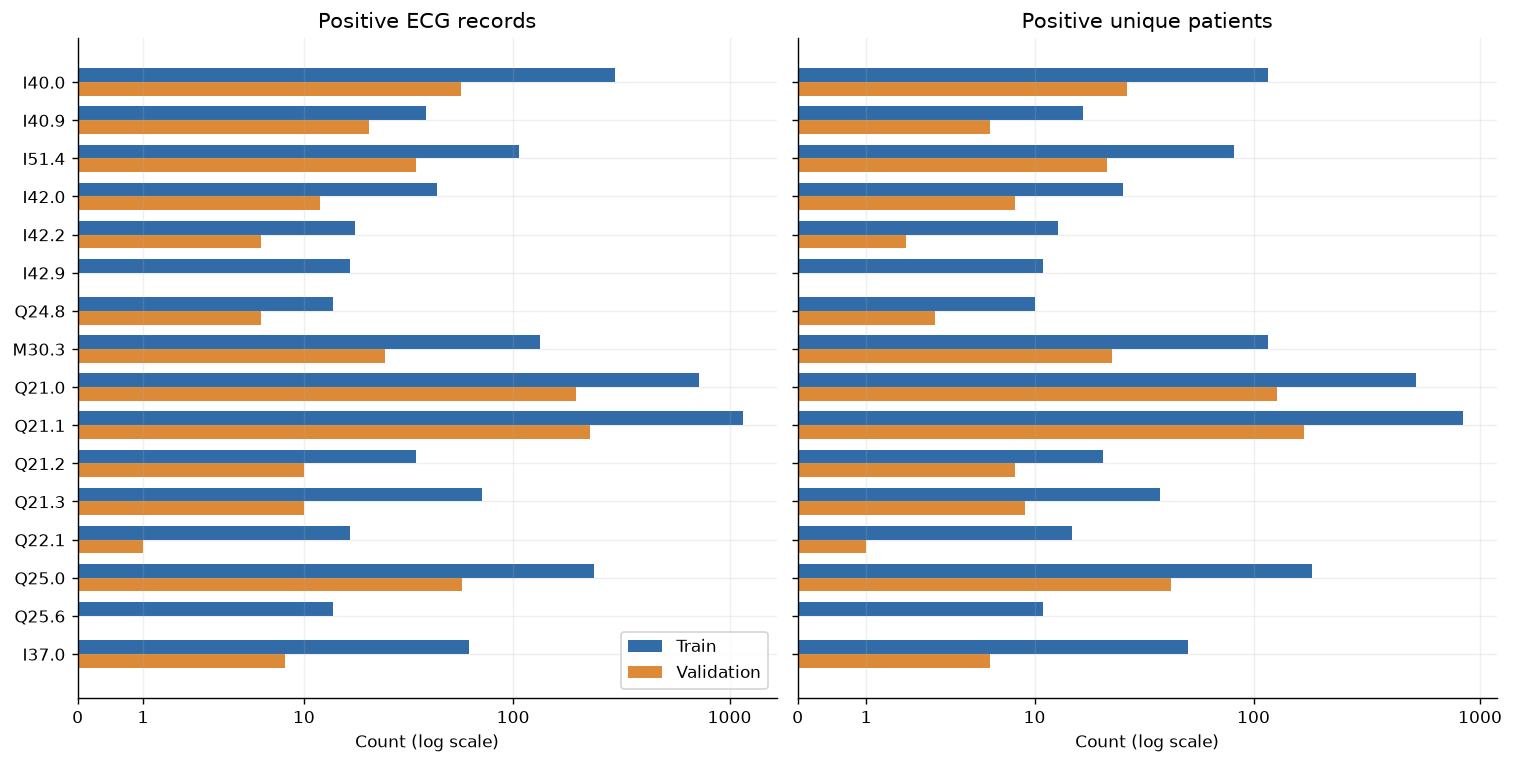

records            patients           
split   train validation    train validation
code                                        
I40.0     296         57      116         27
I40.9      39         21       17          6
I51.4     106         35       82         22
I42.0      44         12       26          8
I42.2      18          6       13          2
I42.9      17          0       11          0
Q24.8      14          6       10          3
M30.3     134         25      116         23
Q21.0     723        196      525        127
Q21.1    1158        226      845        167
Q21.2      35         10       21          8
Q21.3      72         10       38          9
Q22.1      17          1       15          1
Q25.0     236         58      182         43
Q25.6      14          0       11          0
I37.0      62          8       51          6

In [4]:
config=json.loads((BASE/'config.json').read_text())
support=pd.read_csv(BASE/'target_support.csv')
assert len(support)==32 and set(support['code'])==set(codes)
display(pd.DataFrame([{'item':'patient split','value':config['patient_split']},
 {'item':'train records / patients','value':f"{config['train_records']:,} / {config['train_patients']:,}"},
 {'item':'validation records / patients','value':f"{config['validation_records']:,} / {config['validation_patients']:,}"},
 {'item':'waveform input','value':config['preprocessing']},
 {'item':'architecture','value':config['architecture']},
 {'item':'optimization','value':f"{config['loss']}; Adam lr={config['learning_rate']}, weight decay={config['weight_decay']}; batch={config['batch_size']}"},
 {'item':'checkpoint selection','value':config['checkpoint_selection']}]))
fig,axes=plt.subplots(1,2,figsize=(12,6),sharey=True,layout='constrained')
for ax,field,title in zip(axes,['records','patients'],['Positive ECG records','Positive unique patients']):
 t=support.pivot(index='code',columns='split',values=field).reindex(codes)
 y=np.arange(len(codes));h=.36
 ax.barh(y-h/2,np.log10(t['train'].to_numpy()+1),height=h,label='Train',color='#326ca8')
 ax.barh(y+h/2,np.log10(t['validation'].to_numpy()+1),height=h,label='Validation',color='#dc8a38')
 ticks=np.array([0,1,10,100,1000]);ax.set_xticks(np.log10(ticks+1),[str(x) for x in ticks])
 ax.set_xlabel('Count (log scale)');ax.set_title(title);ax.set_yticks(y,codes)
axes[0].invert_yaxis();axes[0].legend(loc='lower right')
plt.show()
display(support.pivot(index='code',columns='split',values=['records','patients']).reindex(codes))

**Finding.** The preserved split has **9,943 training records from 8,150 patients** and **2,169 validation records from 1,746 patients**. The model uses the same patient split, raw first 5,000 samples at 500 Hz, 12 anatomical lead slots, and per-present-lead normalization as the earlier disease-labelled ResNet workflow. Support is highly uneven: `Q21.1` and `Q21.0` dominate, while `I42.9` and `Q25.6` have **zero validation positives**. Only **six** targets have at least ten positive validation patients. Bar lengths use a log scale so the rare targets remain visible.

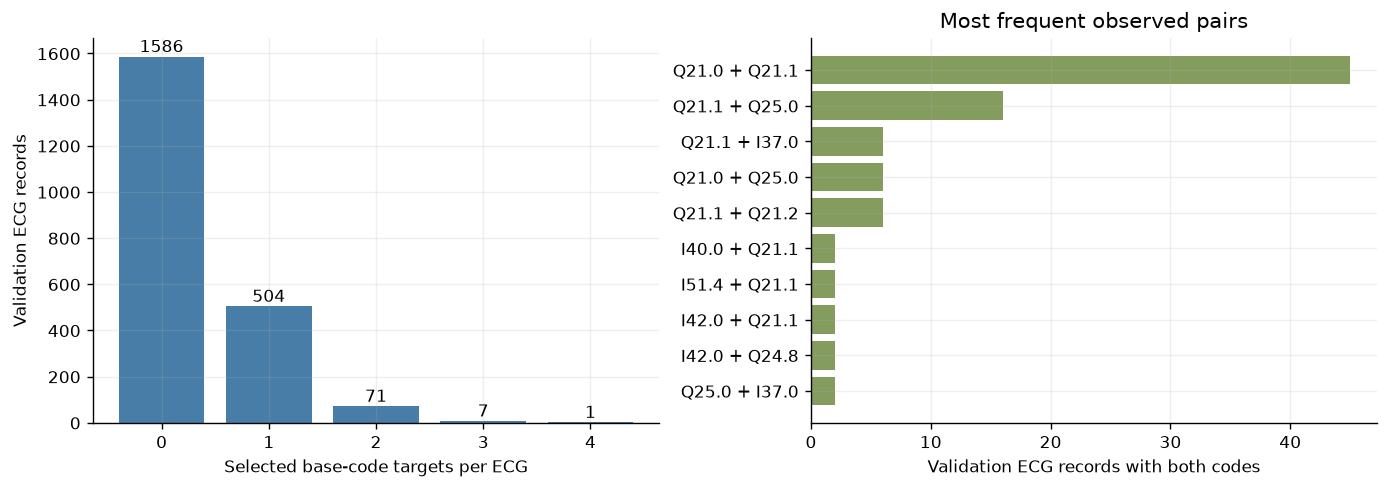

Validation selected-code assignments: 671 | any selected code: 583 | 2+ selected codes: 79


,code A,code B,records
7,Q21.0,Q21.1,45
12,Q21.1,Q25.0,16
13,Q21.1,I37.0,6
9,Q21.0,Q25.0,6
10,Q21.1,Q21.2,6
0,I40.0,Q21.1,2
2,I51.4,Q21.1,2
4,I42.0,Q21.1,2
3,I42.0,Q24.8,2
16,Q25.0,I37.0,2


In [5]:
baseline=pd.read_csv(BASE/'validation_predictions.csv',dtype={'patient_id':str,'ecg_id':str})
assert len(baseline)==2169 and baseline['patient_id'].nunique()==1746
target_cols=[f'target::{c}' for c in codes];prob_cols=[f'probability::{c}' for c in codes]
assert all(c in baseline.columns for c in target_cols+prob_cols)
Y=baseline[target_cols].to_numpy(dtype=int)
assert set(np.unique(Y)).issubset({0,1})
card=Y.sum(axis=1)
fig,axes=plt.subplots(1,2,figsize=(11,3.8),layout='constrained')
vals,counts=np.unique(card,return_counts=True)
axes[0].bar(vals,counts,color='#477da7');axes[0].set_xticks(vals)
axes[0].set_xlabel('Selected base-code targets per ECG');axes[0].set_ylabel('Validation ECG records')
for x,n in zip(vals,counts):axes[0].text(x,n+20,str(n),ha='center')
co=Y.T@Y;pair_rows=[]
for i in range(len(codes)):
 for j in range(i+1,len(codes)):
  if co[i,j]: pair_rows.append((codes[i],codes[j],int(co[i,j])))
pairs=pd.DataFrame(pair_rows,columns=['code A','code B','records']).sort_values('records',ascending=False)
top=pairs.head(10).iloc[::-1]
axes[1].barh(top['code A']+' + '+top['code B'],top['records'],color='#849d5f')
axes[1].set_xlabel('Validation ECG records with both codes');axes[1].set_title('Most frequent observed pairs')
plt.show()
print('Validation selected-code assignments:',int(Y.sum()),'| any selected code:',int((card>0).sum()),
      '| 2+ selected codes:',int((card>=2).sum()))
display(pairs.head(10))

**Finding.** On validation, **671** positive code assignments occur across **583** ECGs; **79** ECGs have at least two selected base codes. The 1,586 records with no selected positive target are *not* a healthy control cohort. The pair chart shows annotation co-occurrence, not causal or physiological interaction between conditions.

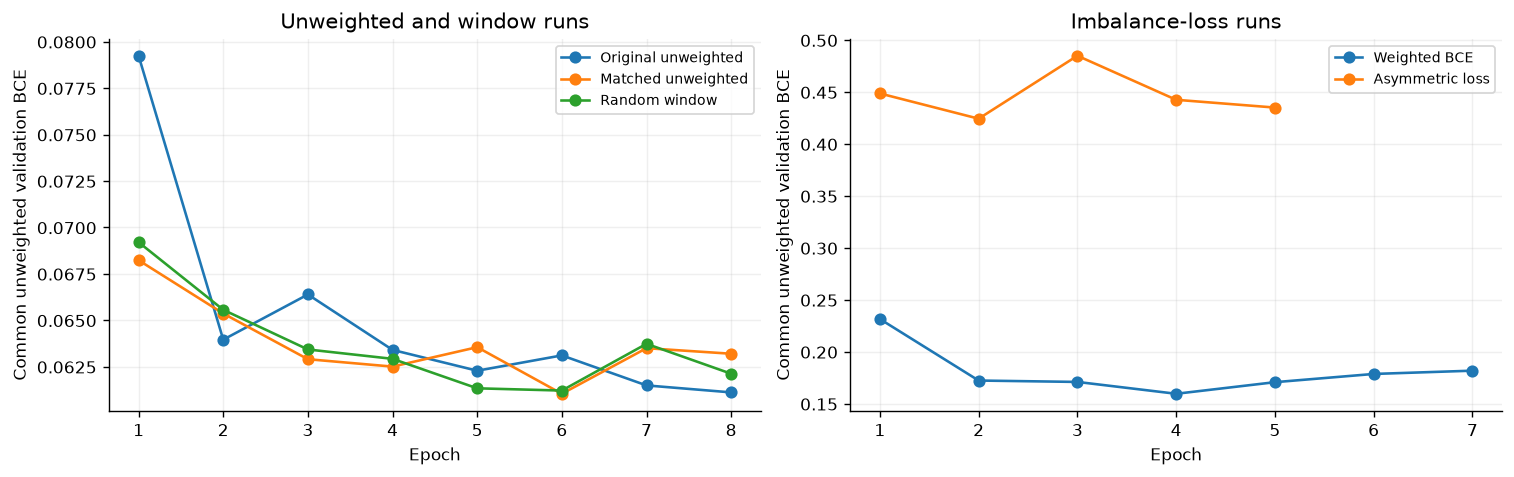

,run,epochs_recorded,minimum_validation_BCE,minimum_BCE_epoch
0,Original unweighted,8,0.06112,8
1,Matched unweighted,8,0.06104,6
2,Weighted BCE,7,0.15965,4
3,Asymmetric loss,5,0.42440,2
4,Random window,8,0.06122,6


In [6]:
histories={'Original unweighted':pd.read_csv(BASE/'training_history.csv'),
 'Matched unweighted':pd.read_csv(IMB/'unweighted_replicate_history.csv'),
 'Weighted BCE':pd.read_csv(IMB/'weighted_bce_history.csv'),
 'Asymmetric loss':pd.read_csv(IMB/'asymmetric_loss_history.csv'),
 'Random window':pd.read_csv(WIN/'random_window_history.csv')}
fig,axes=plt.subplots(1,2,figsize=(12,3.7),layout='constrained')
for name in ['Original unweighted','Matched unweighted','Random window']:
 h=histories[name];v='validation_bce' if 'validation_bce' in h else 'validation_unweighted_bce'
 axes[0].plot(h['epoch'],h[v],marker='o',label=name)
for name in ['Weighted BCE','Asymmetric loss']:
 h=histories[name];axes[1].plot(h['epoch'],h['validation_unweighted_bce'],marker='o',label=name)
for ax in axes:
 ax.set_xlabel('Epoch');ax.set_ylabel('Common unweighted validation BCE');ax.legend(fontsize=8)
axes[0].set_title('Unweighted and window runs');axes[1].set_title('Imbalance-loss runs')
plt.show()
display(pd.DataFrame([{'run':name,'epochs_recorded':len(h),
 'minimum_validation_BCE':h['validation_bce' if 'validation_bce' in h else 'validation_unweighted_bce'].min(),
 'minimum_BCE_epoch':int(h.loc[h['validation_bce' if 'validation_bce' in h else 'validation_unweighted_bce'].idxmin(),'epoch'])}
 for name,h in histories.items()]).round(5))

**Finding.** The original unweighted checkpoint was saved at epoch **8** (validation BCE **0.06112**). The matched unweighted and random-window runs selected epoch **6**; weighted BCE selected epoch **4**, and asymmetric loss epoch **2**, using the common unweighted validation BCE rule. The weighted and asymmetric training objectives have different scales and must not be compared as raw training losses. Their poorer unweighted validation BCE indicates different probability calibration as well as possible discrimination changes; AP and AUROC are checked separately below.

In [7]:
sources={'Original first window':BASE/'validation_predictions.csv',
 'Matched unweighted':IMB/'unweighted_replicate_validation_predictions.csv',
 'Weighted BCE':IMB/'weighted_bce_validation_predictions.csv',
 'Asymmetric loss':IMB/'asymmetric_loss_validation_predictions.csv',
 'Random-window first':WIN/'random_window_first_validation_predictions.csv',
 'Original three mean':WIN/'baseline_three_mean_validation_predictions.csv',
 'Original three MAX':WIN/'baseline_three_max_validation_predictions.csv',
 'Random three mean':WIN/'random_window_three_mean_validation_predictions.csv',
 'Random three MAX':WIN/'random_window_three_max_validation_predictions.csv'}
P={}
for name,path in sources.items():
 d=pd.read_csv(path,dtype={'patient_id':str,'ecg_id':str})
 assert d[['patient_id','ecg_id']].equals(baseline[['patient_id','ecg_id']]),name
 p=d[prob_cols].to_numpy(dtype=float)
 assert p.shape==Y.shape and np.isfinite(p).all() and ((p>=0)&(p<=1)).all(),name
 P[name]=p
assert np.allclose(P['Original first window'],P['Random-window first']) is False
def score(y,p,t=.5):
 z=p>=t;tp=int(((y==1)&z).sum());tn=int(((y==0)&(~z)).sum())
 fp=int(((y==0)&z).sum());fn=int(((y==1)&(~z)).sum())
 valid=[j for j in range(y.shape[1]) if 0<y[:,j].sum()<len(y)]
 return {'TP':tp,'FP':fp,'FN':fn,'TN':tn,'sensitivity':tp/(tp+fn),'specificity':tn/(tn+fp),
  'precision':tp/(tp+fp),'F1':2*tp/(2*tp+fp+fn),
  'micro AUROC':roc_auc_score(y.ravel(),p.ravel()),'micro AP':average_precision_score(y.ravel(),p.ravel()),
  'macro AUROC':np.mean([roc_auc_score(y[:,j],p[:,j]) for j in valid]),
  'macro AP':np.mean([average_precision_score(y[:,j],p[:,j]) for j in valid])}
summary=pd.DataFrame([{'strategy':name,**score(Y,p)} for name,p in P.items()]).set_index('strategy')
stored=json.loads((BASE/'aggregate_validation.json').read_text())
assert summary.loc['Original first window','TP']==stored['micro_tp']
assert summary.loc['Original first window','FP']==stored['micro_fp']
assert np.isclose(summary.loc['Original first window','micro AP'],stored['micro_average_precision'],atol=1e-10)
assert np.isclose(summary.loc['Original first window','macro AP'],stored['macro_average_precision_defined_targets'],atol=1e-10)
display(summary.round(4))

,TP,FP,FN,TN,sensitivity,specificity,precision,F1,micro AUROC,micro AP,macro AUROC,macro AP
strategy,,,,,,,,,,,,
Original first window,147,67,524,33966,0.2191,0.9980,0.6869,0.3322,0.9131,0.3999,0.8283,0.1639
Matched unweighted,125,49,546,33984,0.1863,0.9986,0.7184,0.2959,0.9133,0.3990,0.8375,0.1819
Weighted BCE,402,1845,269,32188,0.5991,0.9458,0.1789,0.2755,0.9126,0.2850,0.8294,0.1441
Asymmetric loss,495,4288,176,29745,0.7377,0.8740,0.1035,0.1815,0.8929,0.2876,0.7913,0.1370
Random-window first,125,38,546,33995,0.1863,0.9989,0.7669,0.2998,0.9141,0.3918,0.8334,0.1598
Original three mean,137,59,534,33974,0.2042,0.9983,0.6990,0.3160,0.9152,0.3951,0.8307,0.1632
Original three MAX,159,81,512,33952,0.2370,0.9976,0.6625,0.3491,0.9150,0.3962,0.8339,0.1643
Random three mean,117,35,554,33998,0.1744,0.9990,0.7697,0.2843,0.9163,0.3917,0.8335,0.1605
Random three MAX,136,52,535,33981,0.2027,0.9985,0.7234,0.3166,0.9168,0.3934,0.8439,0.1596


**Finding.** The saved probabilities reproduce the published baseline counts and AP exactly. At threshold 0.5, the original model has **147 TP / 67 FP / 524 FN**, sensitivity **0.219**, specificity **0.998**, F1 **0.332**, micro AUROC **0.913**, micro AP **0.400**, and macro AP **0.164**. Micro metrics pool all 16 code-record decisions and can be dominated by frequent targets; macro ranking averages only the **14** targets with validation positives. These are annotation-prediction metrics, not clinical diagnostic accuracy.

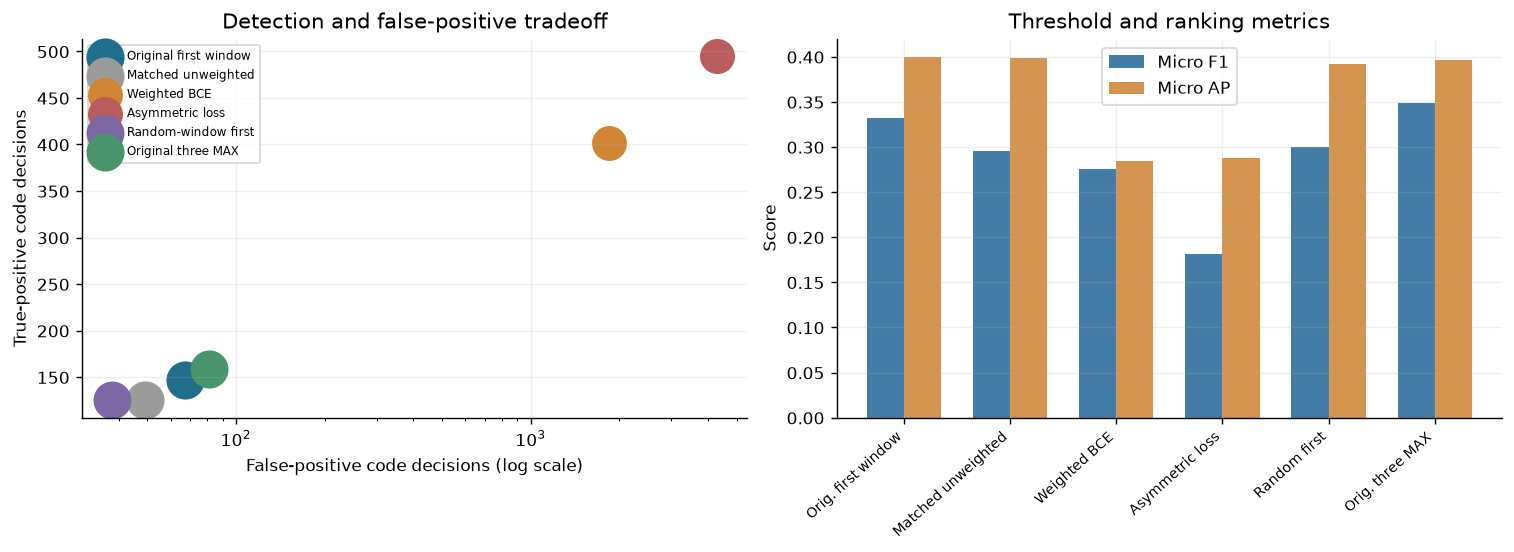

In [8]:
names=['Original first window','Matched unweighted','Weighted BCE','Asymmetric loss',
       'Random-window first','Original three MAX']
pal=['#1f6e8c','#9b9b9b','#d08434','#b85c5c','#7c66a4','#4a946c']
fig,axes=plt.subplots(1,2,figsize=(12,4.3),layout='constrained')
for name,color in zip(names,pal):
 r=summary.loc[name]
 axes[0].scatter(r['FP'],r['TP'],s=180+650*r['micro AP'],color=color,label=name)
axes[0].set_xscale('log');axes[0].set_xlabel('False-positive code decisions (log scale)')
axes[0].set_ylabel('True-positive code decisions');axes[0].set_title('Detection and false-positive tradeoff')
axes[0].legend(fontsize=7,loc='upper left')
x=np.arange(len(names));w=.35
axes[1].bar(x-w/2,summary.loc[names,'F1'],width=w,label='Micro F1',color='#447ca8')
axes[1].bar(x+w/2,summary.loc[names,'micro AP'],width=w,label='Micro AP',color='#d4944f')
axes[1].set_xticks(x,[n.replace('Original ','Orig. ').replace('Random-window','Random') for n in names],rotation=42,ha='right',fontsize=8)
axes[1].set_ylabel('Score');axes[1].set_title('Threshold and ranking metrics');axes[1].legend()
plt.show()

**Finding.** Positive-weighted BCE raises true-positive decisions from **147 to 402** but false positives from **67 to 1,845**, lowering precision, F1, and AP. Asymmetric loss raises true positives to **495** with **4,288** false positives and lower AUROC/AP. The training losses were motivated by [PyTorch's positive-weighted BCE](https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html) and the [asymmetric-loss paper](https://openaccess.thecvf.com/content/ICCV2021/papers/Ridnik_Asymmetric_Loss_for_Multi-Label_Classification_ICCV_2021_paper.pdf); their use here is exploratory. More recall at an unchanged threshold is not, by itself, an overall improvement.

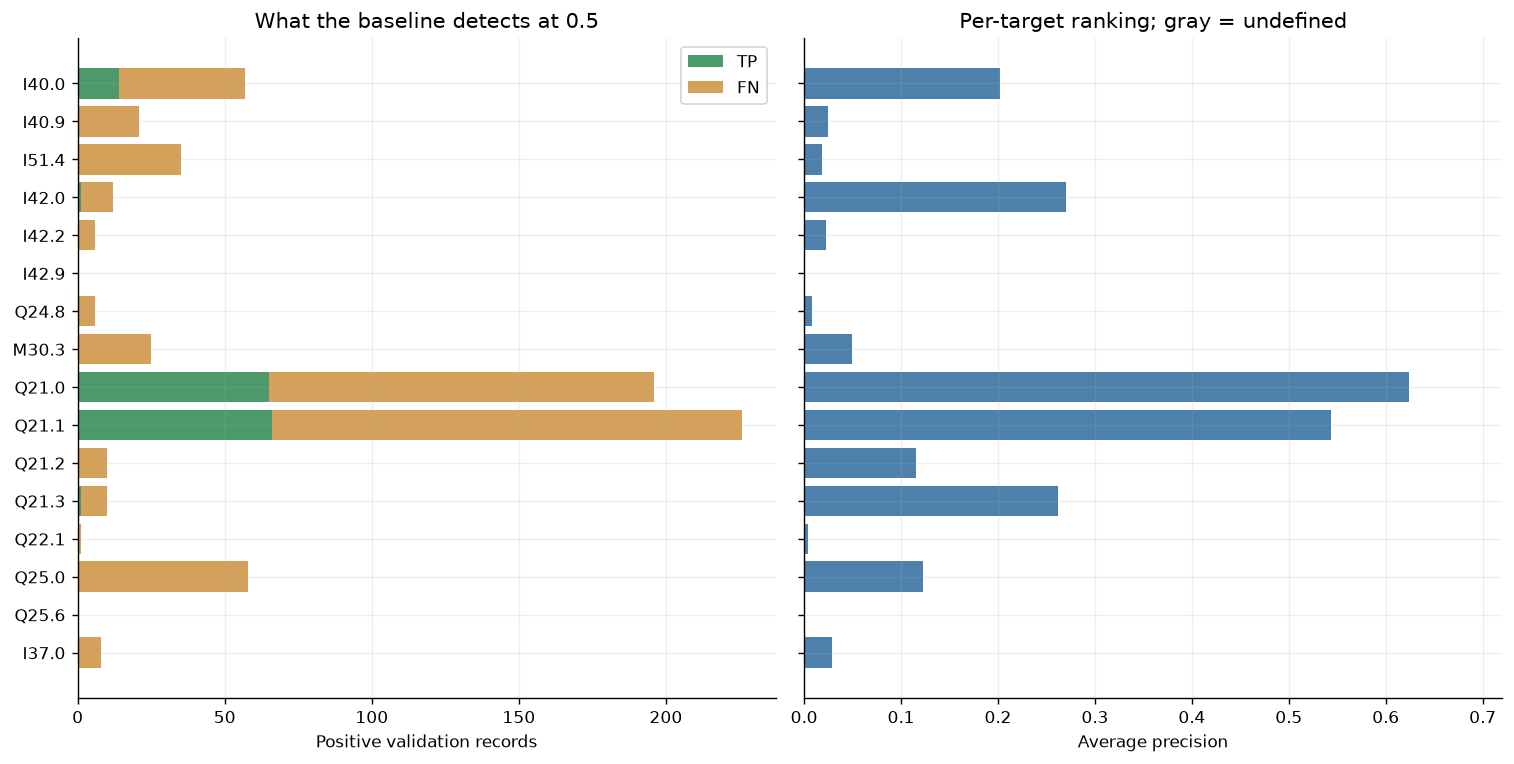

,positive_records,positive_patients,tp,fp,fn,sensitivity,auroc,average_precision,status
code,,,,,,,,,
I40.0,57,27,14,21,43,0.246,0.714,0.202,measurable
I40.9,21,6,0,0,21,0.000,0.741,0.025,<10_positive_patients
I51.4,35,22,0,0,35,0.000,0.560,0.018,measurable
I42.0,12,8,1,0,11,0.083,0.883,0.270,<10_positive_patients
I42.2,6,2,0,0,6,0.000,0.902,0.023,<10_positive_patients
I42.9,0,0,0,0,0,NaN,NaN,NaN,no_validation_positive
Q24.8,6,3,0,0,6,0.000,0.806,0.008,<10_positive_patients
M30.3,25,23,0,0,25,0.000,0.779,0.050,measurable
Q21.0,196,127,65,21,131,0.332,0.911,0.624,measurable


In [9]:
per=pd.read_csv(BASE/'per_target_validation.csv').set_index('code').reindex(codes)
fig,axes=plt.subplots(1,2,figsize=(12,6),sharey=True,layout='constrained')
y=np.arange(len(codes));axes[0].barh(y,per['tp'],color='#4c9a6a',label='TP')
axes[0].barh(y,per['fn'],left=per['tp'],color='#d3a15a',label='FN')
axes[0].set_yticks(y,codes);axes[0].invert_yaxis();axes[0].set_xlabel('Positive validation records')
axes[0].set_title('What the baseline detects at 0.5');axes[0].legend()
ap=per['average_precision'];colors=['#4d81ac' if np.isfinite(v) else '#c5c5c5' for v in ap]
axes[1].barh(y,ap.fillna(0),color=colors)
axes[1].set_xlabel('Average precision');axes[1].set_xlim(0,.72)
axes[1].set_title('Per-target ranking; gray = undefined')
plt.show()
display(per[['positive_records','positive_patients','tp','fp','fn','sensitivity','auroc','average_precision','status']].round(3))

**Finding.** At 0.5, only **five** of 16 targets have any true positives, and **145 of 147** true-positive decisions are for `I40.0`, `Q21.0`, and `Q21.1`. Some targets have apparently high AUROC despite zero detected positives because AUROC measures ranking over all thresholds. `I42.9` and `Q25.6` have no validation positives, so their AP, AUROC, and sensitivity are undefined. Per-target estimates with only a few positive patients are unstable.

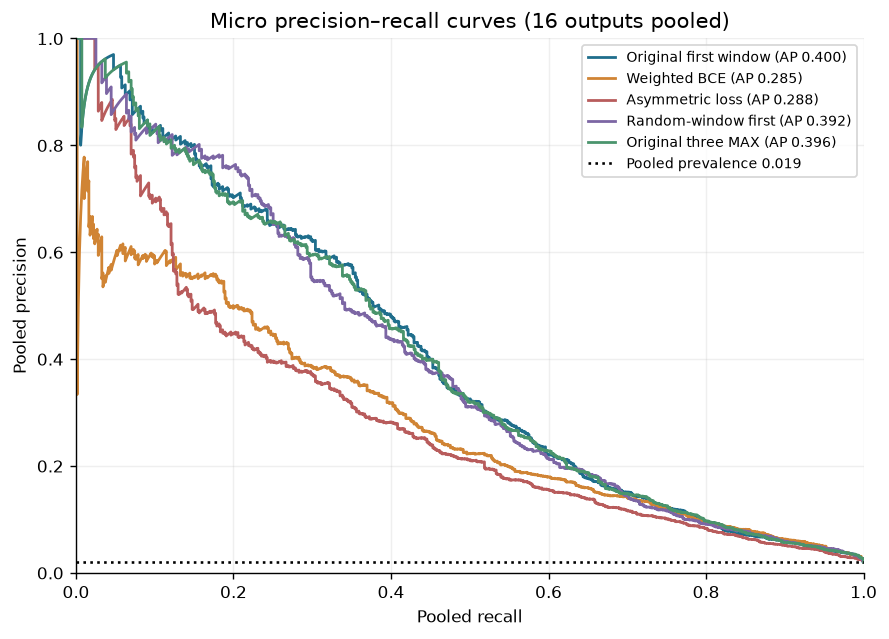

In [10]:
fig,ax=plt.subplots(figsize=(7,5),layout='constrained')
for name,color in [('Original first window','#1f6e8c'),('Weighted BCE','#d08434'),
                   ('Asymmetric loss','#b85c5c'),('Random-window first','#7c66a4'),
                   ('Original three MAX','#4a946c')]:
 precision,recall,_=precision_recall_curve(Y.ravel(),P[name].ravel())
 ax.plot(recall,precision,label=f"{name} (AP {summary.loc[name,'micro AP']:.3f})",color=color,lw=1.6)
ax.axhline(Y.mean(),color='black',ls=':',label=f'Pooled prevalence {Y.mean():.3f}')
ax.set(xlabel='Pooled recall',ylabel='Pooled precision',title='Micro precision–recall curves (16 outputs pooled)',xlim=(0,1),ylim=(0,1))
ax.legend(fontsize=8,loc='upper right');plt.show()

**Finding.** The weighted and asymmetric models' higher sensitivity at threshold 0.5 is accompanied by lower precision across much of the pooled recall range. Random-window training and original three-window MAX do not improve pooled AP over the original first-window baseline. Pooled PR curves emphasize frequent code assignments; per-code evidence is needed before claiming benefit for rare targets.

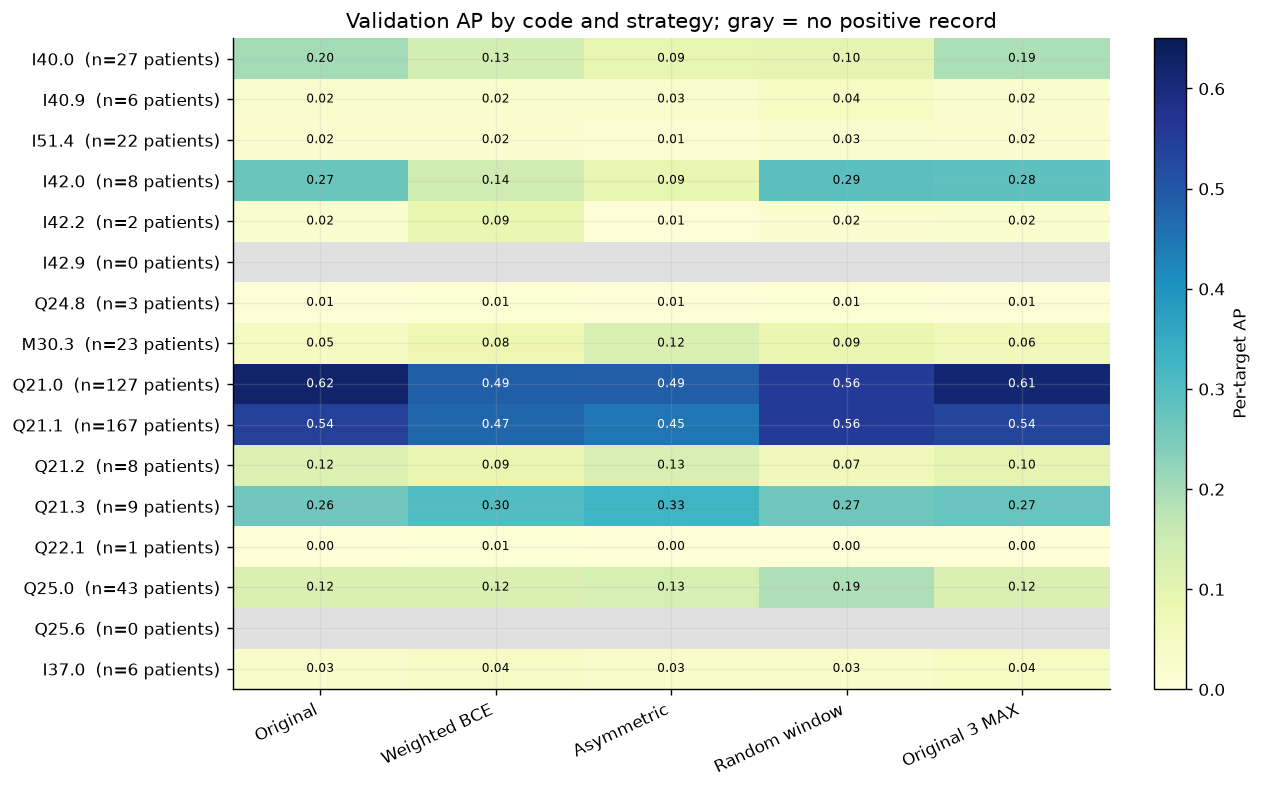

In [11]:
models=['Original first window','Weighted BCE','Asymmetric loss','Random-window first','Original three MAX']
matrix=np.full((len(codes),len(models)),np.nan)
for i,c in enumerate(codes):
 for j,name in enumerate(models):
  yy=Y[:,i]
  if 0<yy.sum()<len(yy):matrix[i,j]=average_precision_score(yy,P[name][:,i])
fig,ax=plt.subplots(figsize=(10,6.2),layout='constrained')
cmap=plt.cm.YlGnBu.copy();cmap.set_bad('#e0e0e0')
im=ax.imshow(np.ma.masked_invalid(matrix),cmap=cmap,vmin=0,vmax=.65,aspect='auto')
ax.set_xticks(np.arange(len(models)),['Original','Weighted BCE','Asymmetric','Random window','Original 3 MAX'],rotation=25,ha='right')
ax.set_yticks(np.arange(len(codes)),[f"{c}  (n={int(per.loc[c,'positive_patients'])} patients)" for c in codes])
for i in range(len(codes)):
 for j in range(len(models)):
  if np.isfinite(matrix[i,j]):
   color='white' if matrix[i,j]>.43 else 'black'
   ax.text(j,i,f'{matrix[i,j]:.2f}',ha='center',va='center',fontsize=7,color=color)
fig.colorbar(im,ax=ax,label='Per-target AP')
ax.set_title('Validation AP by code and strategy; gray = no positive record')
plt.show()

**Finding.** No candidate improves AP consistently across the 14 evaluable targets. For example, random-window training increases `Q25.0` AP from about **0.12 to 0.19** but lowers `I40.0` from about **0.20 to 0.10**. Such differences are descriptive, especially for targets represented by few patients. The gray rows cannot be compared on validation at all.

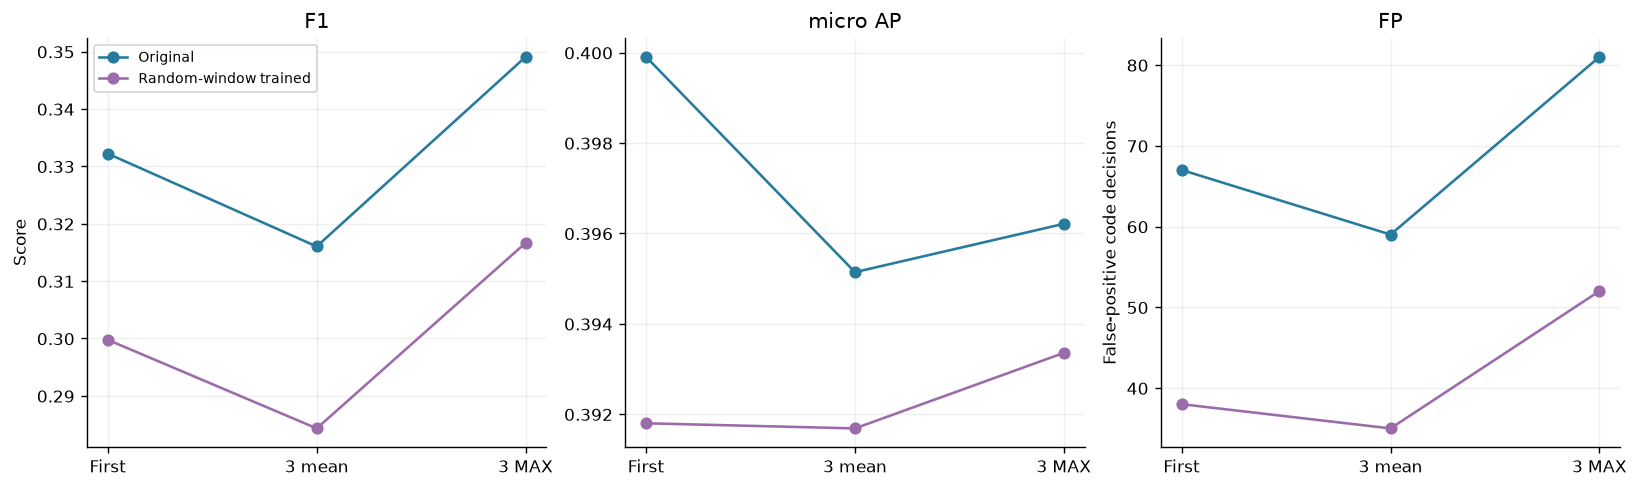

,TP,FP,FN,sensitivity,specificity,precision,F1,micro AUROC,micro AP,macro AP
strategy,,,,,,,,,,
Original first window,147,67,524,0.2191,0.9980,0.6869,0.3322,0.9131,0.3999,0.1639
Original three mean,137,59,534,0.2042,0.9983,0.6990,0.3160,0.9152,0.3951,0.1632
Original three MAX,159,81,512,0.2370,0.9976,0.6625,0.3491,0.9150,0.3962,0.1643
Random-window first,125,38,546,0.1863,0.9989,0.7669,0.2998,0.9141,0.3918,0.1598
Random three mean,117,35,554,0.1744,0.9990,0.7697,0.2843,0.9163,0.3917,0.1605
Random three MAX,136,52,535,0.2027,0.9985,0.7234,0.3166,0.9168,0.3934,0.1596


In [12]:
window_names=['Original first window','Original three mean','Original three MAX',
              'Random-window first','Random three mean','Random three MAX']
fig,axes=plt.subplots(1,3,figsize=(13,3.8),layout='constrained')
xx=np.arange(3)
for label,keys,color in [('Original',['Original first window','Original three mean','Original three MAX'],'#277b9d'),
                          ('Random-window trained',['Random-window first','Random three mean','Random three MAX'],'#9c6caa')]:
 for ax,metric in zip(axes,['F1','micro AP','FP']):
  ax.plot(xx,summary.loc[keys,metric],marker='o',label=label,color=color)
for ax,metric in zip(axes,['F1','micro AP','FP']):
 ax.set_xticks(xx,['First','3 mean','3 MAX']);ax.set_title(metric)
axes[0].set_ylabel('Score');axes[2].set_ylabel('False-positive code decisions')
axes[0].legend(fontsize=8);plt.show()
display(summary.loc[window_names,['TP','FP','FN','sensitivity','specificity','precision','F1','micro AUROC','micro AP','macro AP']].round(4))

**Finding.** Random-window training changes the training segment but does not establish a first-window gain over its matched unweighted replication: both have **125 TP**, while random-window has **38 versus 49 FP** and micro AP **0.392 versus 0.399**. On the unchanged original checkpoint, three-window MAX yields **159 TP / 81 FP / 512 FN**, F1 **0.349**, and AP **0.396** versus first-window **147 / 67 / 524**, F1 **0.332**, AP **0.400**. Three-window mean does not improve F1. The inference aggregation changes the operating tradeoff; it is not a new trained model.

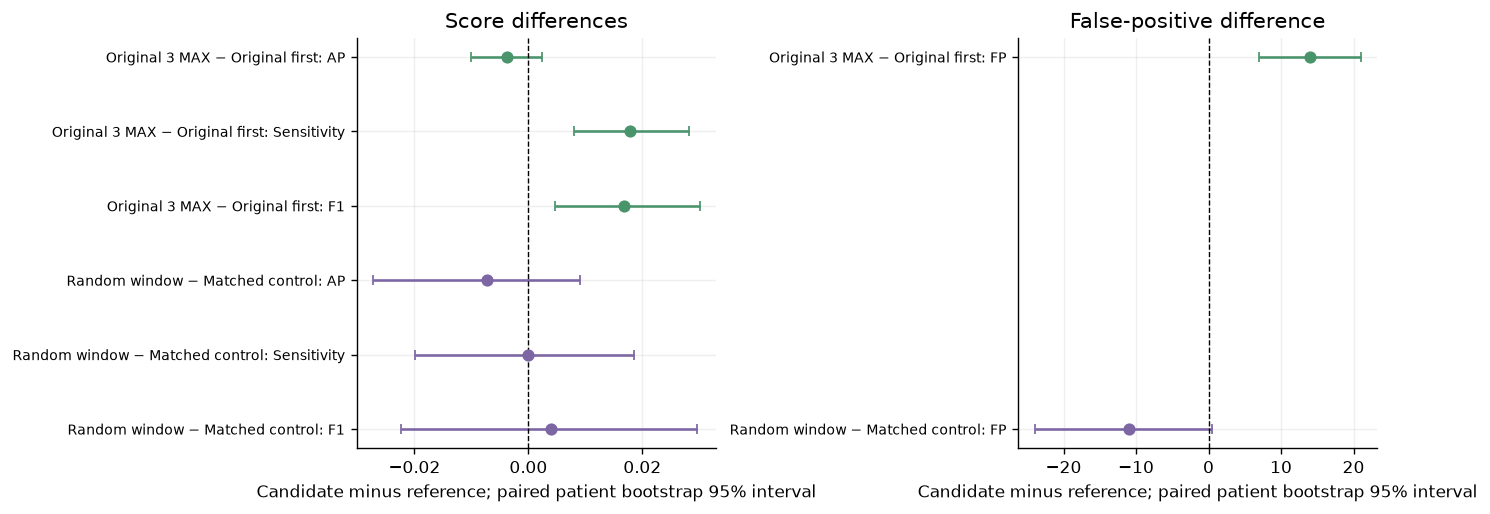

,candidate,reference,metric,observed_delta,patient_bootstrap_95pct_low,patient_bootstrap_95pct_high,replicates
0,random_window_first,matched_unweighted_first,micro_f1,0.0039,-0.0224,0.0297,500
1,random_window_first,matched_unweighted_first,micro_sensitivity,0.0000,-0.0199,0.0185,500
2,random_window_first,matched_unweighted_first,false_positives,-11.0000,-24.0000,0.5250,500
3,random_window_first,matched_unweighted_first,micro_average_precision,-0.0072,-0.0272,0.0091,500
4,baseline_three_max,baseline_first,micro_f1,0.0169,0.0047,0.0301,500
5,baseline_three_max,baseline_first,micro_sensitivity,0.0179,0.0080,0.0282,500
6,baseline_three_max,baseline_first,false_positives,14.0000,7.0000,21.0000,500
7,baseline_three_max,baseline_first,micro_average_precision,-0.0037,-0.0101,0.0025,500


In [13]:
boot=pd.read_csv(WIN/'paired_patient_bootstrap.csv')
fig,axes=plt.subplots(1,2,figsize=(11,4),layout='constrained')
for ax,metric_list in zip(axes,[['micro_f1','micro_sensitivity','micro_average_precision'],['false_positives']]):
 subset=boot[boot['metric'].isin(metric_list)]
 for j,(_,r) in enumerate(subset.iterrows()):
  color='#4a946c' if r['candidate']=='baseline_three_max' else '#7c66a4'
  ax.errorbar(r['observed_delta'],j,xerr=[[r['observed_delta']-r['patient_bootstrap_95pct_low']],
             [r['patient_bootstrap_95pct_high']-r['observed_delta']]],fmt='o',color=color,capsize=3)
 short={'random_window_first':'Random window','matched_unweighted_first':'Matched control',
        'baseline_three_max':'Original 3 MAX','baseline_first':'Original first',
        'micro_f1':'F1','micro_sensitivity':'Sensitivity','micro_average_precision':'AP','false_positives':'FP'}
 ax.set_yticks(range(len(subset)),[f"{short[r['candidate']]} − {short[r['reference']]}: {short[r['metric']]}" for _,r in subset.iterrows()],fontsize=8)
 ax.axvline(0,color='black',lw=.8,ls='--');ax.set_xlabel('Candidate minus reference; paired patient bootstrap 95% interval')
axes[0].set_title('Score differences');axes[1].set_title('False-positive difference')
plt.show()
display(boot.round(4))

**Finding.** In **500 paired patient bootstrap resamples**, random-window versus matched unweighted F1 differs by **+0.0039** with interval **−0.0224 to +0.0297**: no stable advantage is established. Original three-window MAX versus original first-window F1 differs by **+0.0169** (interval **+0.0047 to +0.0301**) and adds **14 FP** (interval **+7 to +21**); its AP difference is **−0.0037** with an interval spanning zero. These intervals reflect resampling within the same repeatedly used validation cohort and do not remove model-selection or strategy-selection optimism.

In [14]:
required=[BASE/'resnet1d_base16_best.pth',BASE/'training_history.csv',BASE/'target_mapping.json',
 IMB/'unweighted_replicate_best.pth',IMB/'weighted_bce_best.pth',IMB/'asymmetric_loss_best.pth',
 IMB/'unweighted_replicate_history.csv',IMB/'weighted_bce_history.csv',IMB/'asymmetric_loss_history.csv',
 WIN/'random_window_best.pth',WIN/'random_window_history.csv',
 BASE/'Week7_Base16_Multilabel.ipynb',IMB/'Week7_Imbalance_Strategies.ipynb',WIN/'Week7_Window_Augmentation.ipynb']
audit=pd.DataFrame({'artifact':[str(p.relative_to(W7)) for p in required],
                    'exists':[p.is_file() for p in required],
                    'bytes':[p.stat().st_size if p.is_file() else np.nan for p in required]})
assert audit['exists'].all()
display(audit)
print('Validated',len(required),'essential artifacts; frozen test set not accessed by this notebook.')

,artifact,exists,bytes
0,experimental/multilabel_base16/resnet1d_base16...,True,2244642
1,experimental/multilabel_base16/training_histor...,True,371
2,experimental/multilabel_base16/target_mapping....,True,1210
3,experimental/imbalance_strategies/unweighted_r...,True,2245762
4,experimental/imbalance_strategies/weighted_bce...,True,2244930
5,experimental/imbalance_strategies/asymmetric_l...,True,2245218
6,experimental/imbalance_strategies/unweighted_r...,True,573
7,experimental/imbalance_strategies/weighted_bce...,True,500
8,experimental/imbalance_strategies/asymmetric_l...,True,380
9,experimental/window_augmentation/random_window...,True,2245026


Validated 14 essential artifacts; frozen test set not accessed by this notebook.


## Consolidated decision and limits

**Primary Week 7 multilabel model:** retain `experimental/multilabel_base16/resnet1d_base16_best.pth`, selected at epoch 8 by minimum unweighted validation BCE. Preserve all four additional experimental checkpoints and their histories. The loss changes are negative results for overall validation performance. Random-window training is inconclusive against its matched control. Three-window MAX on the original checkpoint is a **candidate inference strategy**, with a modest F1/sensitivity gain and more false positives; it has no AP gain and has not been independently confirmed.

**Interpretation limits:** deposited inpatient diagnosis codes can be incomplete, and code absence is not confirmed disease absence. Repeated ECGs from a patient are correlated. Very rare targets and two zero-positive validation targets cannot support reliable per-code claims. The same validation partition was used for checkpoint selection and exploratory strategy comparison, so it cannot provide an unbiased final estimate after these decisions. No test evaluation, external validation, or clinical adjudication has been performed here. Grad-CAM or other explanations from earlier binary work do not establish causality for this multilabel model.

**Reproduction:** Run this notebook with the existing project virtual environment to regenerate every table and chart from saved Week 7 artifacts. The source training notebooks document waveform loading, target construction, optimizer settings, checkpoint selection, and all exploratory runs. No file in an earlier week is modified.